# AI Package Damage Detection System
### Image & Video Processing (AIDLL 5052) — Practical No. 8: Mini Project

**Name:** ____________________ &nbsp;&nbsp; **Roll No.:** __________ &nbsp;&nbsp; **Date:** __________

---

**Problem.** Warehouses and courier hubs handle thousands of parcels every hour. Manually checking each box for
damage is slow and inconsistent. This project builds an automatic visual inspection system that looks at an image of a
package and decides:

1. **Is the package damaged?** → `ACCEPT` / `REJECT`
2. **What kind of damage?** → `intact`, `crushed` (dented / crushed corner), `torn` (holes / rips), `stained` (water / liquid stains)
3. **Where is the damage?** → bounding boxes drawn on the image + a severity estimate

**Pipeline overview**

| Stage | Image-processing techniques used |
|---|---|
| 1. Pre-processing | Colour-space conversion (BGR → HSV / LAB / Gray), Gaussian blur, CLAHE contrast enhancement |
| 2. Segmentation | Otsu thresholding on the saturation channel, morphological opening/closing, contour extraction |
| 3. Feature extraction | Shape (solidity, convexity defects, polygon approximation), Canny edge density, Laplacian variance, colour statistics, Local Binary Pattern (LBP) texture |
| 4. Classification (AI) | Random Forest on hand-crafted features + a Convolutional Neural Network (CNN) on raw pixels → ensemble |
| 5. Localisation | Adaptive dark-region thresholding (tears), illumination correction + luminance-drop detection (stains), convexity-defect analysis (crushes) |

In [1]:
import os, glob, time, warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
import torch.nn as nn
import torch.nn.functional as F
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams['figure.dpi'] = 90
IMG = 128                                         # working resolution
CLASSES = ['intact', 'crushed', 'torn', 'stained']

def rgb(img):                                     # OpenCV (BGR) -> matplotlib (RGB)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print('OpenCV', cv2.__version__, '| PyTorch', torch.__version__)

OpenCV 5.0.0 | PyTorch 2.13.0+cpu


## 1. Dataset

Real labelled datasets of damaged parcels are scarce, so the notebook contains a **procedural package image generator**
that renders cardboard boxes on a conveyor belt with realistic variation:

* random size, rotation, perspective, cardboard shade, corrugation texture, lighting gradient, exposure, blur and noise
* distractors that must **not** be flagged as damage: packing tape, white shipping labels with barcodes, printed "this-side-up" arrows, conveyor slats
* three damage types: **crushed** corners (concave contour + crease lines + shading), **torn** holes (dark irregular openings with a frayed edge) and **water stains** (darkened blotches with a tide-line ring)

> If a real dataset is available, place it as `dataset/intact/*.jpg`, `dataset/crushed/*.jpg`, `dataset/torn/*.jpg`,
> `dataset/stained/*.jpg` and the notebook will automatically use it instead of the generator.

In [2]:
def _background(rng):
    bg = np.full((IMG, IMG, 3), rng.uniform(70, 150), np.float32) + rng.uniform(-8, 8, 3)
    bg += rng.normal(0, 5, (IMG, IMG, 1))
    if rng.random() < 0.5:                                    # conveyor-belt slats
        bg[::int(rng.integers(10, 18))] -= 18
    return bg

def _box_corners(rng):
    cx, cy = IMG / 2 + rng.uniform(-6, 6, 2)
    w, h = rng.uniform(32, 46, 2)
    a = np.deg2rad(rng.uniform(-15, 15))
    R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    pts = np.array([[-w, -h], [w, -h], [w, h], [-w, h]]) @ R.T + [cx, cy]
    return pts + rng.uniform(-3, 3, pts.shape)                # slight perspective distortion

def _inside_point(rng, c, margin=0.2):
    u, v = rng.uniform(margin, 1 - margin, 2)
    top, bot = c[0] + u * (c[1] - c[0]), c[3] + u * (c[2] - c[3])
    return top + v * (bot - top)

def _pt(p):
    return tuple(int(round(v)) for v in p)

def _col(c):
    return tuple(float(v) for v in c)

def make_package(label, rng):
    img = _background(rng)
    corners = _box_corners(rng)
    centre = corners.mean(0)
    poly = list(corners)

    if label == 'crushed':                                    # push one corner inwards
        i = int(rng.integers(4))
        c, a, b = corners[i], corners[i - 1], corners[(i + 1) % 4]
        e1 = c + rng.uniform(0.12, 0.33) * (a - c)
        e2 = c + rng.uniform(0.12, 0.33) * (b - c)
        dent = c + rng.uniform(0.3, 0.55) * (centre - c)
        poly = poly[:i] + [e1, dent, e2] + poly[i + 1:]

    mask = np.zeros((IMG, IMG), np.uint8)
    cv2.fillPoly(mask, [np.int32(np.round(poly))], 255)

    colour = np.array([75, 135, 185], np.float32) + rng.uniform(-18, 18, 3)   # cardboard (BGR)
    box = np.ones((IMG, IMG, 3), np.float32) * colour
    yy, xx = np.mgrid[0:IMG, 0:IMG]
    box *= (1 + 0.03 * np.sin(xx * rng.uniform(0.8, 1.4)))[..., None]       # corrugation
    box *= (1 + rng.normal(0, 0.04, (IMG, IMG)))[..., None]                 # paper grain
    gx, gy = rng.uniform(-0.0015, 0.0015, 2)
    box *= (1 + gx * (xx - IMG / 2) + gy * (yy - IMG / 2))[..., None]       # lighting gradient

    if rng.random() < 0.8:                                    # packing tape
        tape = np.zeros_like(mask)
        cv2.line(tape, _pt((corners[0] + corners[1]) / 2), _pt((corners[3] + corners[2]) / 2),
                 255, int(rng.integers(6, 11)))
        box[tape > 0] = box[tape > 0] * 1.12 + 12
    if rng.random() < 0.6:                                    # shipping label with barcode
        p = _inside_point(rng, corners, 0.3)
        lw, lh = int(rng.integers(10, 16)), int(rng.integers(7, 11))
        x0, y0 = int(p[0] - lw / 2), int(p[1] - lh / 2)
        cv2.rectangle(box, (x0, y0), (x0 + lw, y0 + lh), (235, 235, 235), -1)
        for k in range(x0 + 2, x0 + lw - 1, 2):
            if rng.random() < 0.7:
                cv2.line(box, (k, y0 + 2), (k, y0 + lh - 3), (30, 30, 30), 1)
    if rng.random() < 0.4:                                    # printed "this side up" arrows
        x, y = _pt(_inside_point(rng, corners, 0.25))
        for dx in (0, 5):
            cv2.arrowedLine(box, (x + dx, y + 6), (x + dx, y - 6), (40, 50, 60), 1, tipLength=0.4)

    if label == 'crushed':                                    # creases + shadow at the dent
        for _ in range(int(rng.integers(2, 4))):
            ang, L = rng.uniform(0, 2 * np.pi), rng.uniform(8, 18)
            cv2.line(box, _pt(dent), _pt(dent + L * np.array([np.cos(ang), np.sin(ang)])), _col(colour * 0.55), 1)
        shade = np.zeros((IMG, IMG), np.float32)
        cv2.circle(shade, _pt(dent), int(rng.integers(8, 14)), 1.0, -1)
        box *= (1 - 0.25 * cv2.GaussianBlur(shade, (0, 0), 4))[..., None]

    if label == 'torn':                                       # irregular holes with frayed edge
        for _ in range(int(rng.integers(1, 3))):
            c = _inside_point(rng, corners, 0.2)
            n, r = int(rng.integers(8, 15)), rng.uniform(3.5, 12)
            angs = np.sort(rng.uniform(0, 2 * np.pi, n))
            hole = np.int32(c + np.c_[np.cos(angs), np.sin(angs)] * (r * rng.uniform(0.5, 1.3, n))[:, None])
            cv2.fillPoly(box, [hole], _col(colour * rng.uniform(0.2, 0.35)))
            cv2.polylines(box, [hole], True, _col(np.minimum(colour * 1.35, 255)), 1)

    if label == 'stained':                                    # water stain with tide-line ring
        st = np.zeros((IMG, IMG), np.float32)
        for _ in range(int(rng.integers(1, 3))):
            ax = (int(rng.integers(8, 20)), int(rng.integers(8, 20)))
            cv2.ellipse(st, _pt(_inside_point(rng, corners, 0.25)), ax, rng.uniform(0, 180), 0, 360, 1.0, -1)
        st = np.clip(cv2.GaussianBlur(st, (0, 0), 3), 0, 1)
        ring = 4 * st * (1 - st)
        strength = rng.uniform(0.15, 0.32)                        # faint to strong stains
        box *= (1 - strength * st - 0.4 * strength * ring)[..., None]
        box[..., 0] *= (1 - 0.1 * st)

    m = mask > 0
    img[m] = box[m]
    img = cv2.GaussianBlur(img, (0, 0), rng.uniform(0.3, 1.0))
    img += rng.normal(0, 3, img.shape)
    img *= rng.uniform(0.85, 1.15)                            # exposure
    return np.clip(img, 0, 255).astype(np.uint8)

Generated synthetic package dataset
Images: (1600, 128, 128, 3) | per class: {'intact': 400, 'crushed': 400, 'torn': 400, 'stained': 400}


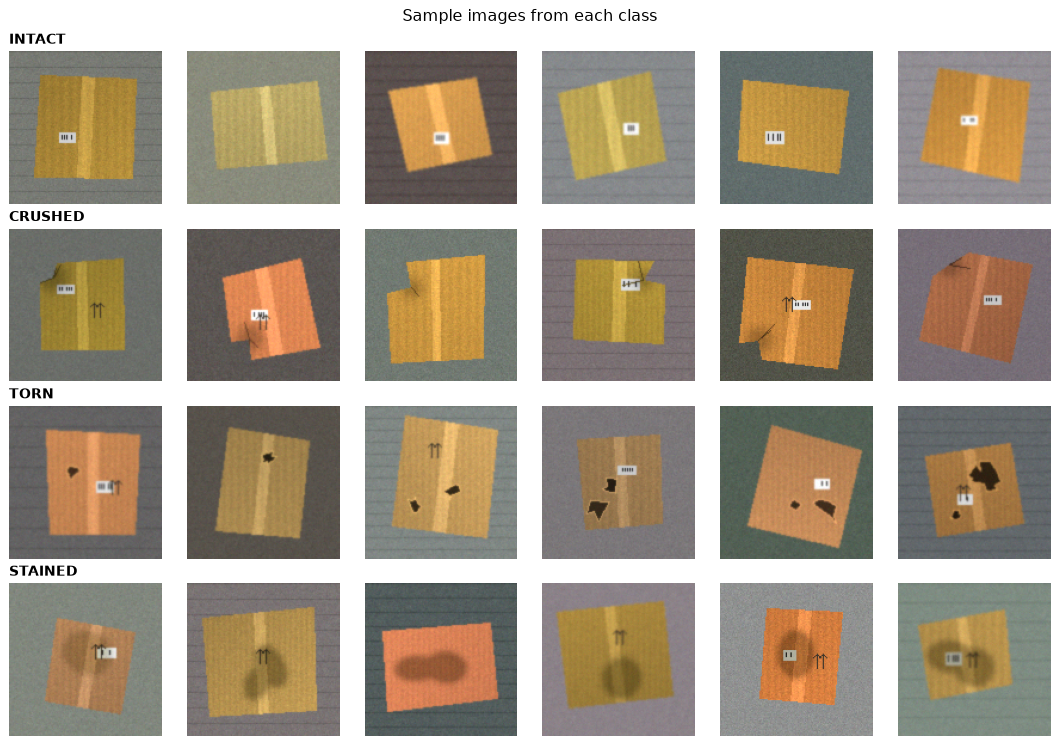

In [3]:
DATA_DIR = 'dataset'
N_PER_CLASS = 400

def load_dataset():
    if all(os.path.isdir(os.path.join(DATA_DIR, c)) for c in CLASSES):
        X, y = [], []
        for ci, c in enumerate(CLASSES):
            for f in sorted(glob.glob(os.path.join(DATA_DIR, c, '*'))):
                im = cv2.imread(f)
                if im is not None:
                    X.append(cv2.resize(im, (IMG, IMG))); y.append(ci)
        print(f'Loaded real dataset from "{DATA_DIR}/"')
        return np.array(X), np.array(y)
    rng = np.random.default_rng(SEED)
    X = [make_package(c, rng) for c in CLASSES for _ in range(N_PER_CLASS)]
    y = [ci for ci in range(len(CLASSES)) for _ in range(N_PER_CLASS)]
    print('Generated synthetic package dataset')
    return np.array(X), np.array(y)

X, y = load_dataset()
print('Images:', X.shape, '| per class:', dict(zip(CLASSES, np.bincount(y).tolist())))

fig, axes = plt.subplots(4, 6, figsize=(12, 8.4))
for r, c in enumerate(CLASSES):
    idx = np.where(y == r)[0][:6]
    for k, i in enumerate(idx):
        axes[r, k].imshow(rgb(X[i])); axes[r, k].axis('off')
    axes[r, 0].set_title(c.upper(), loc='left', fontsize=11, fontweight='bold')
plt.suptitle('Sample images from each class', fontsize=13)
plt.tight_layout(); plt.show()

## 2. Pre-processing & Package Segmentation

Cardboard is a strongly **saturated** colour, whereas conveyor belts, floors and walls are mostly grey. So the package is
isolated by:

1. converting BGR → **HSV** and taking the **S (saturation)** channel
2. **Gaussian blur** (5×5) to suppress noise
3. **Otsu's thresholding** — automatically picks the threshold that best separates the bimodal histogram
4. **Morphological opening** (removes specks) and **closing** (fills small gaps)
5. **Contour extraction** — the largest external contour is the package; filling it gives the package mask
   (white labels and dark holes inside the box are automatically included)

The grey channel is also enhanced with **CLAHE** (Contrast-Limited Adaptive Histogram Equalisation) before edge detection.

In [4]:
KERNEL5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

def segment_package(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    s = cv2.GaussianBlur(hsv[..., 1], (5, 5), 0)
    _, th = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN, KERNEL5)
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, KERNEL5, iterations=2)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not cnts:                                     # fallback: whole image is the package
        h, w = img.shape[:2]
        cnt = np.array([[[0, 0]], [[w - 1, 0]], [[w - 1, h - 1]], [[0, h - 1]]], np.int32)
    else:
        cnt = max(cnts, key=cv2.contourArea)
    mask = np.zeros(img.shape[:2], np.uint8)
    cv2.drawContours(mask, [cnt], -1, 255, -1)
    return mask, cnt, th

def _lbp(gray):
    g = gray.astype(np.int16)
    c = g[1:-1, 1:-1]
    code = np.zeros(c.shape, np.uint8)
    offsets = [(-1, -1), (-1, 0), (-1, 1), (0, 1), (1, 1), (1, 0), (1, -1), (0, -1)]
    for bit, (dy, dx) in enumerate(offsets):
        nb = g[1 + dy:g.shape[0] - 1 + dy, 1 + dx:g.shape[1] - 1 + dx]
        code |= (nb >= c).astype(np.uint8) << bit
    return np.pad(code, 1)

def _uniform_bin(code):                              # rotation-invariant uniform LBP -> 10 bins
    b = [(code >> i) & 1 for i in range(8)]
    transitions = sum(b[i] != b[(i + 1) % 8] for i in range(8))
    return sum(b) if transitions <= 2 else 9

LBP_LUT = np.array([_uniform_bin(i) for i in range(256)], np.uint8)

def lbp_image(gray):
    return LBP_LUT[_lbp(gray)]

def relative_luminance(img, inner):
    # LAB lightness divided by a least-squares plane fitted over the package -> removes uneven lighting
    L = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[..., 0], (7, 7), 0).astype(np.float32)
    yy, xx = np.mgrid[0:L.shape[0], 0:L.shape[1]]
    A = np.c_[xx[inner], yy[inner], np.ones(inner.sum())]
    keep = np.ones(len(A), bool)
    for _ in range(2):                                # refit ignoring outliers (stains, holes, labels)
        coef = np.linalg.lstsq(A[keep], L[inner][keep], rcond=None)[0]
        ratio = L[inner] / (A @ coef + 1e-6)
        keep = (ratio > 0.92) & (ratio < 1.12)
    return L / (coef[0] * xx + coef[1] * yy + coef[2] + 1e-6)

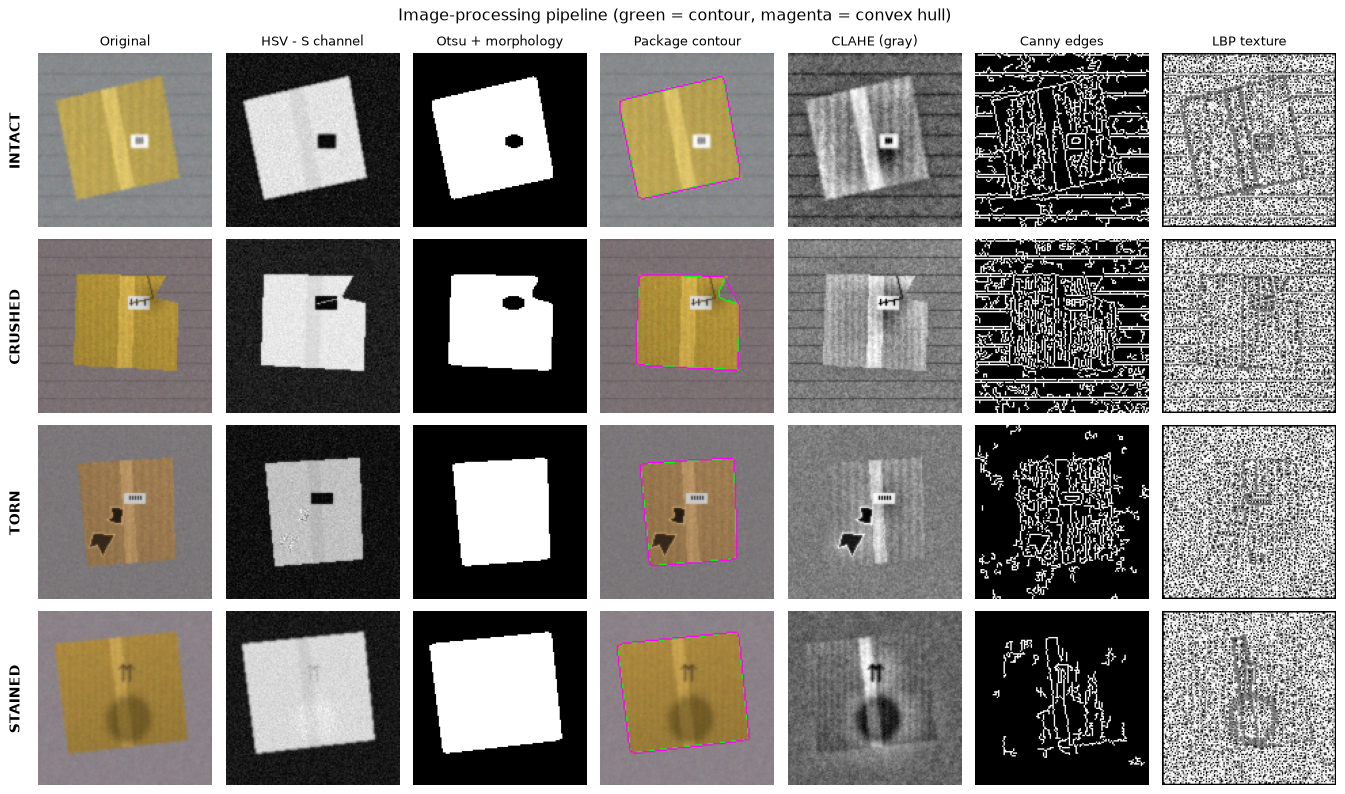

In [5]:
sample = {c: X[np.where(y == ci)[0][3]] for ci, c in enumerate(CLASSES)}

fig, axes = plt.subplots(4, 7, figsize=(15, 9))
titles = ['Original', 'HSV - S channel', 'Otsu + morphology', 'Package contour',
          'CLAHE (gray)', 'Canny edges', 'LBP texture']
for r, c in enumerate(CLASSES):
    img = sample[c]
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask, cnt, th = segment_package(img)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(2.0, (8, 8)).apply(gray)
    cont = rgb(img).copy(); cv2.drawContours(cont, [cnt], -1, (0, 255, 0), 1)
    hull = cv2.convexHull(cnt); cv2.drawContours(cont, [hull], -1, (255, 0, 255), 1)
    panels = [rgb(img), hsv[..., 1], th, cont, clahe, cv2.Canny(clahe, 60, 150), lbp_image(gray)]
    for k, p in enumerate(panels):
        axes[r, k].imshow(p, cmap=None if p.ndim == 3 else 'gray'); axes[r, k].axis('off')
        if r == 0: axes[r, k].set_title(titles[k], fontsize=10)
    axes[r, 0].text(-12, IMG / 2, c.upper(), rotation=90, va='center', ha='right', fontsize=11, fontweight='bold')
plt.suptitle('Image-processing pipeline (green = contour, magenta = convex hull)', fontsize=13)
plt.tight_layout(); plt.show()

## 3. Feature Extraction

For every package 28 features are computed **inside the segmented package region only**:

| Group | Features | Detects |
|---|---|---|
| Shape | area ratio, **solidity** (area / convex-hull area), extent, #polygon vertices, circularity, max & total **convexity-defect depth** | crushed corners make the outline concave |
| Darkness | dark-pixel ratio (V < 50 % of median), largest dark blob | holes / tears expose the dark inside of the box |
| Stain | ratio of pixels with a moderate luminance drop (55–88 % of the illumination-corrected L channel) | water stains |
| Edges | **Canny** edge density on CLAHE image, **Laplacian** variance | creases, torn edges |
| Colour | mean & std of H, S, V | discolouration |
| Texture | 10-bin uniform **LBP** histogram | surface texture changes |

In [6]:
FEATURE_NAMES = (['area_ratio', 'solidity', 'extent', 'n_vertices', 'circularity', 'max_defect', 'sum_defect',
                  'dark_ratio', 'dark_blob', 'stain_ratio', 'edge_density', 'laplacian_var',
                  'H_mean', 'S_mean', 'V_mean', 'H_std', 'S_std', 'V_std'] + [f'lbp_{i}' for i in range(10)])

def convexity_defects(cnt):
    try:
        approx = cv2.approxPolyDP(cnt, 1.0, True)
        d = cv2.convexityDefects(approx, cv2.convexHull(approx, returnPoints=False))
        return approx, (d.reshape(-1, 4) if d is not None else np.zeros((0, 4), int))
    except cv2.error:
        return cnt, np.zeros((0, 4), int)

def extract_features(img):
    mask, cnt, _ = segment_package(img)
    inner = cv2.erode(mask, KERNEL5) > 0
    if inner.sum() < 50: inner = mask > 0
    area = cv2.contourArea(cnt) + 1e-6
    peri = cv2.arcLength(cnt, True) + 1e-6
    solidity = area / (cv2.contourArea(cv2.convexHull(cnt)) + 1e-6)
    _, (rw, rh), _ = cv2.minAreaRect(cnt)
    extent = area / (rw * rh + 1e-6)
    n_vertices = len(cv2.approxPolyDP(cnt, 0.02 * peri, True))
    circularity = 4 * np.pi * area / peri ** 2
    _, d = convexity_defects(cnt)
    depths = d[:, 3] / 256.0 if len(d) else np.array([0.0])
    max_defect = depths.max() / np.sqrt(area)
    sum_defect = depths[depths > 2].sum() / np.sqrt(area)

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    V = hsv[..., 2]
    medV = np.median(V[inner]) + 1e-6
    dark = ((V < 0.5 * medV) & inner).astype(np.uint8)
    dark_ratio = dark[inner].mean()
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(dark)
    dark_blob = stats[1:, cv2.CC_STAT_AREA].max() / area if n > 1 else 0.0

    R = relative_luminance(img, inner)[inner]
    stain_ratio = np.mean((R < 0.88) & (R > 0.55))

    clahe = cv2.createCLAHE(2.0, (8, 8)).apply(gray)
    edge_density = (cv2.Canny(clahe, 60, 150)[inner] > 0).mean()
    lap_var = cv2.Laplacian(gray, cv2.CV_64F)[inner].var()
    hsv_stats = [hsv[..., i][inner].mean() for i in range(3)] + [hsv[..., i][inner].std() for i in range(3)]
    lbp_hist = np.bincount(lbp_image(gray)[inner], minlength=10) / inner.sum()

    return np.array([area / mask.size, solidity, extent, n_vertices, circularity, max_defect, sum_defect,
                     dark_ratio, dark_blob, stain_ratio, edge_density, lap_var] + hsv_stats + list(lbp_hist),
                    np.float32)

t0 = time.time()
Fx = np.stack([extract_features(im) for im in X])
print(f'Feature matrix: {Fx.shape}  ({time.time() - t0:.1f} s)')

Feature matrix: (1600, 28)  (4.1 s)


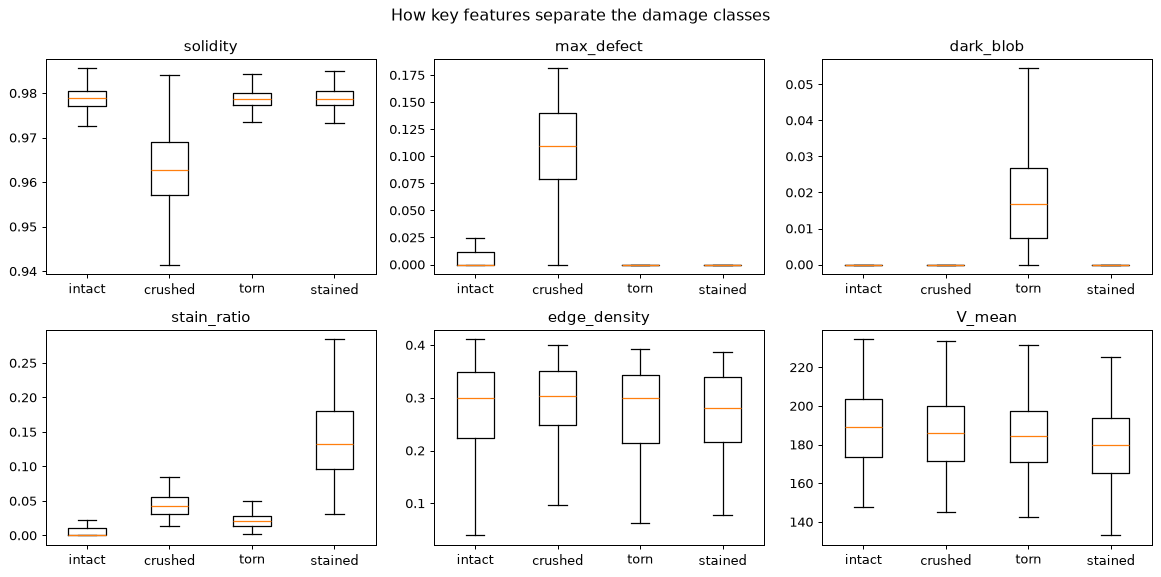

In [7]:
show = ['solidity', 'max_defect', 'dark_blob', 'stain_ratio', 'edge_density', 'V_mean']
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, name in zip(axes.ravel(), show):
    j = FEATURE_NAMES.index(name)
    ax.boxplot([Fx[y == ci, j] for ci in range(len(CLASSES))], showfliers=False)
    ax.set_xticks(range(1, len(CLASSES) + 1), CLASSES); ax.set_title(name)
plt.suptitle('How key features separate the damage classes', fontsize=13)
plt.tight_layout(); plt.show()

## 4. Model 1 — Random Forest on hand-crafted features

The data is split **80 % train / 20 % test** (stratified). A Random Forest of 300 decision trees is trained on the
28-dimensional feature vectors.

Random Forest test accuracy: 99.69 %

              precision    recall  f1-score   support

      intact      1.000     1.000     1.000        80
     crushed      0.988     1.000     0.994        80
        torn      1.000     1.000     1.000        80
     stained      1.000     0.988     0.994        80

    accuracy                          0.997       320
   macro avg      0.997     0.997     0.997       320
weighted avg      0.997     0.997     0.997       320



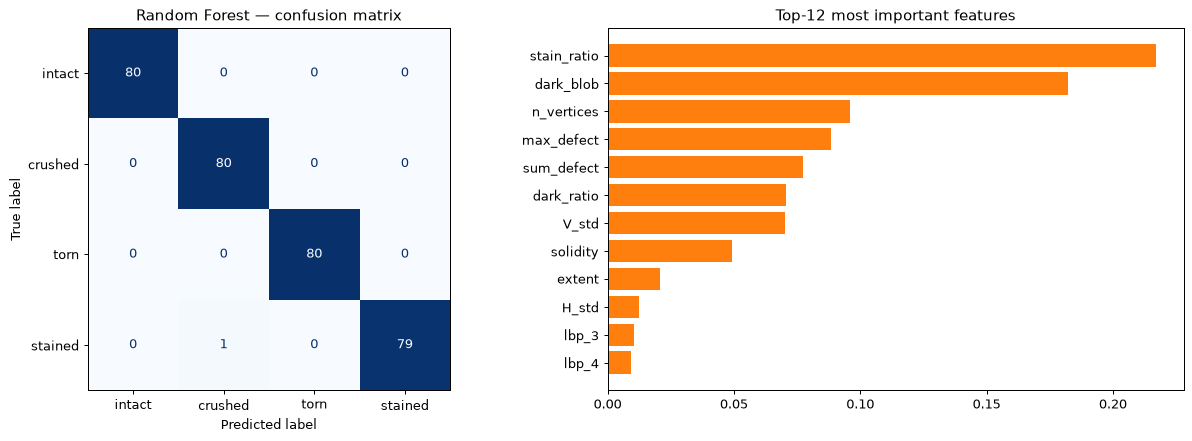

In [8]:
idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)

rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
rf.fit(Fx[idx_train], y[idx_train])
p_rf_test = rf.predict_proba(Fx[idx_test])
acc_rf = accuracy_score(y[idx_test], p_rf_test.argmax(1))
print(f'Random Forest test accuracy: {acc_rf * 100:.2f} %\n')
print(classification_report(y[idx_test], p_rf_test.argmax(1), target_names=CLASSES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(confusion_matrix(y[idx_test], p_rf_test.argmax(1)), display_labels=CLASSES).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Random Forest — confusion matrix')
order = np.argsort(rf.feature_importances_)[-12:]
axes[1].barh([FEATURE_NAMES[i] for i in order], rf.feature_importances_[order], color='tab:orange')
axes[1].set_title('Top-12 most important features')
plt.tight_layout(); plt.show()

## 5. Model 2 — Convolutional Neural Network (deep learning)

A compact CNN learns its own features directly from pixels:

`[Conv3×3 → BatchNorm → ReLU → MaxPool] × 4  →  Global Average Pool  →  Dropout  →  Fully-connected (4 classes)`

Random horizontal / vertical flips are used as **data augmentation**; the Adam optimiser runs with a one-cycle learning-rate schedule for 25 epochs.

In [9]:
class PackageCNN(nn.Module):
    def __init__(self, n_classes=len(CLASSES)):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 16), block(16, 32), block(32, 64), block(64, 64))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

def to_tensor(imgs):
    imgs = np.stack([cv2.cvtColor(i, cv2.COLOR_BGR2RGB) for i in imgs]).astype(np.float32) / 255.0
    return torch.from_numpy(imgs).permute(0, 3, 1, 2)

Xt, yt = to_tensor(X), torch.from_numpy(y).long()
cnn = PackageCNN()
opt = torch.optim.Adam(cnn.parameters(), lr=2e-3)
EPOCHS, BS = 25, 64
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=EPOCHS * int(np.ceil(len(idx_train) / BS)))
history = {'loss': [], 'train_acc': [], 'test_acc': []}

def predict_cnn(x):
    cnn.eval()
    with torch.no_grad():
        return torch.cat([F.softmax(cnn(x[i:i + 256]), 1) for i in range(0, len(x), 256)]).numpy()

t0 = time.time()
for ep in range(EPOCHS):
    cnn.train()
    perm = np.random.permutation(idx_train)
    tot, correct, n = 0.0, 0, 0
    for b in range(0, len(perm), BS):
        xb, yb = Xt[perm[b:b + BS]], yt[perm[b:b + BS]]
        if np.random.rand() < 0.5: xb = xb.flip(3)
        if np.random.rand() < 0.5: xb = xb.flip(2)
        out = cnn(xb)
        loss = F.cross_entropy(out, yb)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        tot += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    test_acc = (predict_cnn(Xt[idx_test]).argmax(1) == y[idx_test]).mean()
    history['loss'].append(tot / n); history['train_acc'].append(correct / n); history['test_acc'].append(test_acc)
    print(f'epoch {ep + 1:2d}/{EPOCHS}  loss {tot / n:.4f}  train acc {correct / n:.3f}  test acc {test_acc:.3f}')
print(f'Training time: {time.time() - t0:.1f} s')

epoch  1/25  loss 1.4523  train acc 0.292  test acc 0.250


epoch  2/25  loss 1.3577  train acc 0.345  test acc 0.297


epoch  3/25  loss 1.2709  train acc 0.421  test acc 0.494


epoch  4/25  loss 1.1591  train acc 0.500  test acc 0.466


epoch  5/25  loss 1.0662  train acc 0.560  test acc 0.506


...

epoch 21/25  loss 0.2845  train acc 0.945  test acc 0.941


epoch 22/25  loss 0.2953  train acc 0.930  test acc 0.947


epoch 23/25  loss 0.2738  train acc 0.941  test acc 0.959


epoch 24/25  loss 0.2798  train acc 0.940  test acc 0.953


epoch 25/25  loss 0.2809  train acc 0.939  test acc 0.956
Training time: 57.5 s


CNN test accuracy: 95.62 %

              precision    recall  f1-score   support

      intact      0.951     0.963     0.957        80
     crushed      0.915     0.938     0.926        80
        torn      1.000     1.000     1.000        80
     stained      0.961     0.925     0.943        80

    accuracy                          0.956       320
   macro avg      0.957     0.956     0.956       320
weighted avg      0.957     0.956     0.956       320



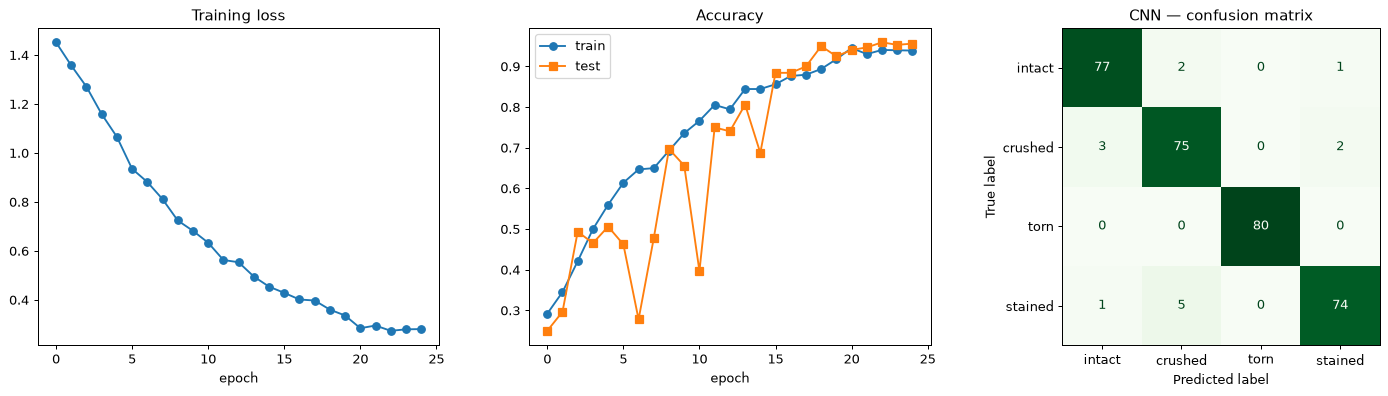

In [10]:
p_cnn_test = predict_cnn(Xt[idx_test])
acc_cnn = accuracy_score(y[idx_test], p_cnn_test.argmax(1))
print(f'CNN test accuracy: {acc_cnn * 100:.2f} %\n')
print(classification_report(y[idx_test], p_cnn_test.argmax(1), target_names=CLASSES, digits=3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(history['loss'], 'o-'); axes[0].set_title('Training loss'); axes[0].set_xlabel('epoch')
axes[1].plot(history['train_acc'], 'o-', label='train'); axes[1].plot(history['test_acc'], 's-', label='test')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend()
ConfusionMatrixDisplay(confusion_matrix(y[idx_test], p_cnn_test.argmax(1)), display_labels=CLASSES).plot(
    ax=axes[2], cmap='Greens', colorbar=False)
axes[2].set_title('CNN — confusion matrix')
plt.tight_layout(); plt.show()

## 6. Ensemble & Binary ACCEPT / REJECT Decision

The final prediction averages the class probabilities of both models. For the warehouse, the most important question is
binary: **intact → ACCEPT**, any damage → **REJECT**.

In [11]:
p_ens_test = 0.5 * p_rf_test + 0.5 * p_cnn_test
acc_ens = accuracy_score(y[idx_test], p_ens_test.argmax(1))

y_bin, pred_bin = y[idx_test] != 0, p_ens_test.argmax(1) != 0
tp, fn = np.sum(y_bin & pred_bin), np.sum(y_bin & ~pred_bin)
fp, tn = np.sum(~y_bin & pred_bin), np.sum(~y_bin & ~pred_bin)

print(f'{"Model":<28}{"4-class accuracy":>18}')
for name, a in [('Random Forest (features)', acc_rf), ('CNN (pixels)', acc_cnn), ('Ensemble (RF + CNN)', acc_ens)]:
    print(f'{name:<28}{a * 100:>17.2f}%')
print('\nBinary damage detection (ensemble):')
print(f'  accuracy  {(tp + tn) / len(y_bin) * 100:.2f} %')
print(f'  recall    {tp / (tp + fn) * 100:.2f} %   (damaged parcels caught)')
print(f'  precision {tp / (tp + fp) * 100:.2f} %   (rejections that were really damaged)')
print(f'  missed damaged parcels: {fn}   |   good parcels wrongly rejected: {fp}')

wrong = idx_test[p_ens_test.argmax(1) != y[idx_test]]
if len(wrong):
    k = min(len(wrong), 6)
    fig, axes = plt.subplots(1, k, figsize=(2.2 * k, 2.6), squeeze=False)
    for ax, i in zip(axes[0], wrong[:k]):
        j = np.where(idx_test == i)[0][0]
        ax.imshow(rgb(X[i])); ax.axis('off')
        ax.set_title(f'true: {CLASSES[y[i]]}\npred: {CLASSES[p_ens_test[j].argmax()]}', fontsize=9, color='red')
    plt.suptitle('Misclassified test images'); plt.tight_layout(); plt.show()

Model                         4-class accuracy
Random Forest (features)                99.69%
CNN (pixels)                            95.62%
Ensemble (RF + CNN)                    100.00%

Binary damage detection (ensemble):
  accuracy  100.00 %
  recall    100.00 %   (damaged parcels caught)
  precision 100.00 %   (rejections that were really damaged)
  missed damaged parcels: 0   |   good parcels wrongly rejected: 0


## 7. Damage Localisation

Classification says *what* is wrong; localisation shows *where*. Three classical image-processing detectors run on
the segmented package:

* **Tears / holes** — pixels darker than 50 % of the package's median brightness (V channel), cleaned with morphological
  opening; each connected component is a hole.
* **Stains** — uneven lighting is first removed by fitting a plane to the LAB lightness of the package (least squares) and dividing it out; regions that are then 55–88 % as bright are stains (darker, but not a hole).
* **Crushes / dents** — **convexity defects** of the package contour: points where the outline caves in deeper than
  5 % of the package size. The shadow around a dent is excluded from stain detection.

**Severity** = damaged area as a percentage of the package area → *Minor* (< 3 %), *Moderate* (3–8 %), *Severe* (> 8 %).

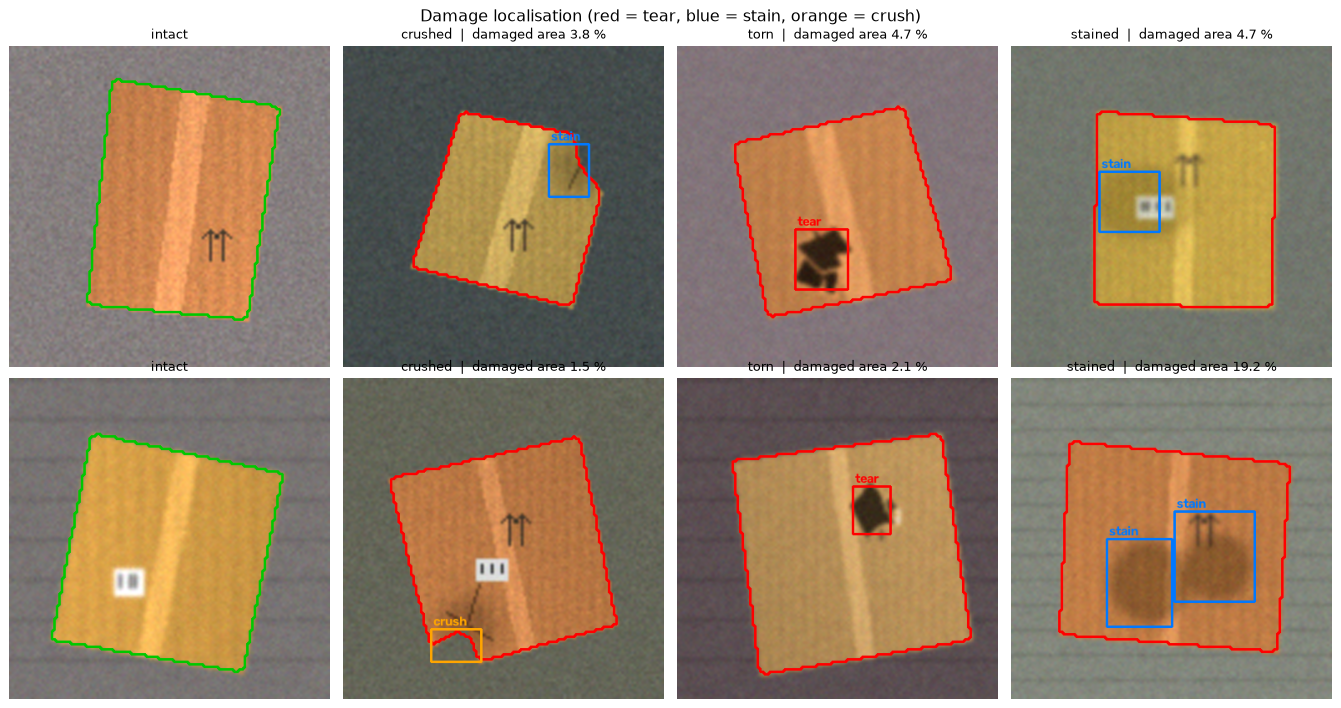

In [12]:
def localize_damage(img):
    mask, cnt, _ = segment_package(img)
    inner = cv2.erode(mask, KERNEL5)
    area = cv2.contourArea(cnt) + 1e-6
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    regions, dmg = [], np.zeros(mask.shape, np.uint8)

    V = hsv[..., 2]; medV = np.median(V[inner > 0])
    dark = (((V < 0.5 * medV) & (inner > 0)) * 255).astype(np.uint8)
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    for c in cv2.findContours(dark, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
        if cv2.contourArea(c) >= 12:
            regions.append(('tear', cv2.boundingRect(c))); cv2.drawContours(dmg, [c], -1, 255, -1)

    crush_zone = np.zeros(mask.shape, np.uint8)               # shadow around a dent is not a stain
    approx, d = convexity_defects(cnt)
    for s, e, f, depth in d:
        if depth / 256.0 > 0.05 * np.sqrt(area):
            tri = approx[[s, e, f], 0]
            regions.append(('crush', cv2.boundingRect(tri))); cv2.fillPoly(dmg, [tri], 255)
            cv2.circle(crush_zone, tuple(int(v) for v in approx[f, 0]), int(0.3 * np.sqrt(area)), 255, -1)

    R = relative_luminance(img, inner > 0)
    stain = (((R < 0.88) & (R >= 0.55) & (inner > 0)) * 255).astype(np.uint8)
    stain[(cv2.dilate(dark, KERNEL5, iterations=2) > 0) | (crush_zone > 0)] = 0
    stain = cv2.morphologyEx(stain, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)))
    for c in cv2.findContours(stain, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
        if cv2.contourArea(c) >= 100:
            regions.append(('stain', cv2.boundingRect(c))); cv2.drawContours(dmg, [c], -1, 255, -1)

    severity_pct = 100 * (dmg > 0).sum() / area
    return regions, cnt, severity_pct

BOX_COLOURS = {'tear': (0, 0, 255), 'stain': (255, 120, 0), 'crush': (0, 165, 255)}   # BGR

def draw_regions(img, regions, cnt, scale=3, damaged=True):
    out = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    cv2.drawContours(out, [cnt * scale], -1, (0, 0, 255) if damaged else (0, 200, 0), 2)
    if damaged:
        for kind, (x, yb, w, h) in regions:
            col = BOX_COLOURS[kind]
            cv2.rectangle(out, (x * scale - 3, yb * scale - 3), ((x + w) * scale + 3, (yb + h) * scale + 3), col, 2)
            cv2.putText(out, kind, (x * scale, max(yb * scale - 7, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 2)
    return out

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for k, c in enumerate(CLASSES):
    for r in range(2):
        img = X[np.where(y == k)[0][10 + r]]
        regions, cnt, sev = localize_damage(img)
        axes[r, k].imshow(rgb(draw_regions(img, regions, cnt, damaged=(c != 'intact')))); axes[r, k].axis('off')
        axes[r, k].set_title(f'{c}  |  damaged area {sev:.1f} %' if c != 'intact' else 'intact', fontsize=10)
plt.suptitle('Damage localisation (red = tear, blue = stain, orange = crush)', fontsize=13)
plt.tight_layout(); plt.show()

## 8. The Complete Inspection System

`inspect_package(image)` is the single function a warehouse camera would call. It runs the whole pipeline —
segmentation → features → RF + CNN ensemble → localisation → severity — and returns an inspection report.

Below it is tested on **brand-new packages that the models have never seen** (generated with a different random seed).

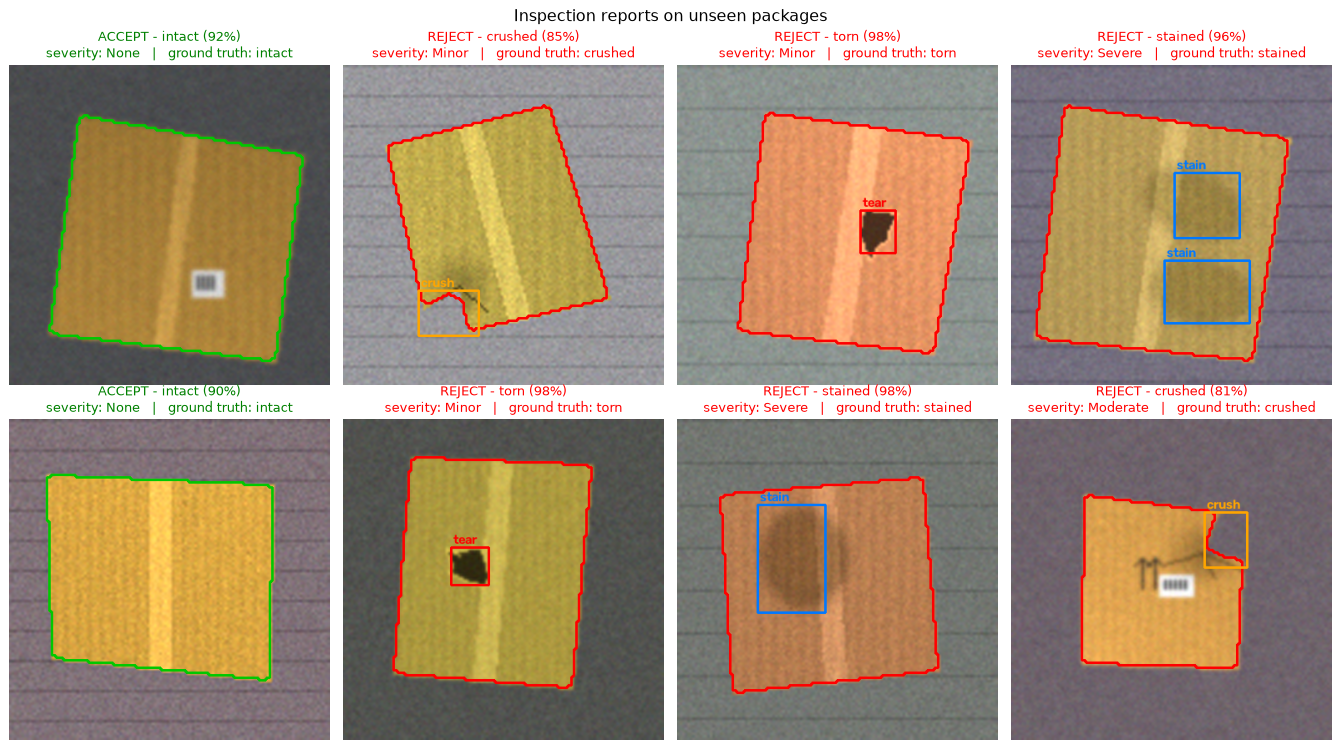

Example report:
  decision         : REJECT
  damage_type      : torn
  confidence       : 0.937
  severity         : Minor
  damaged_area_pct : 0.6
  regions          : [('tear', (44, 38, 8, 7))]
  probabilities    : {'intact': 0.051, 'crushed': 0.004, 'torn': 0.937, 'stained': 0.008}


In [13]:
def inspect_package(img):
    img = cv2.resize(img, (IMG, IMG), interpolation=cv2.INTER_AREA)
    p = 0.5 * rf.predict_proba(extract_features(img)[None])[0] + 0.5 * predict_cnn(to_tensor([img]))[0]
    k = int(p.argmax())
    damaged = CLASSES[k] != 'intact'
    regions, cnt, sev = localize_damage(img)
    if not damaged:
        severity = 'None'
    else:
        severity = 'Minor' if sev < 3 else 'Moderate' if sev < 8 else 'Severe'
    return {'decision': 'REJECT' if damaged else 'ACCEPT', 'damage_type': CLASSES[k], 'confidence': round(float(p[k]), 3),
            'severity': severity, 'damaged_area_pct': round(float(sev), 1) if damaged else 0.0,
            'regions': regions if damaged else [], 'probabilities': dict(zip(CLASSES, np.round(p, 3).tolist())),
            'annotated': draw_regions(img, regions, cnt, damaged=damaged)}

rng_new = np.random.default_rng(2026)
truth = ['intact', 'crushed', 'torn', 'stained', 'intact', 'torn', 'stained', 'crushed']
fig, axes = plt.subplots(2, 4, figsize=(15, 8.6))
for ax, t in zip(axes.ravel(), truth):
    rep = inspect_package(make_package(t, rng_new))
    ax.imshow(rgb(rep['annotated'])); ax.axis('off')
    colour = 'green' if rep['decision'] == 'ACCEPT' else 'red'
    ax.set_title(f"{rep['decision']} - {rep['damage_type']} ({rep['confidence'] * 100:.0f}%)\n"
                 f"severity: {rep['severity']}   |   ground truth: {t}", color=colour, fontsize=10)
plt.suptitle('Inspection reports on unseen packages', fontsize=13)
plt.tight_layout(); plt.show()

rep = inspect_package(make_package('torn', rng_new))
print('Example report:')
for k, v in rep.items():
    if k != 'annotated': print(f'  {k:<17}: {v}')

## 9. Try it on your own photos

Put photos of packages (`.jpg` / `.png`) in a folder called `test_images/` next to this notebook and re-run the cell
below. *(Models trained only on synthetic data will be less reliable on real photos — retraining with a real dataset in
`dataset/` gives the best results.)*

In [14]:
files = sorted(sum([glob.glob(os.path.join('test_images', e)) for e in ('*.jpg', '*.jpeg', '*.png')], []))
if not files:
    print('No images found in test_images/ - add some package photos to test the system on real images.')
else:
    fig, axes = plt.subplots(1, len(files), figsize=(4 * len(files), 4.5), squeeze=False)
    for ax, f in zip(axes[0], files):
        rep = inspect_package(cv2.imread(f))
        ax.imshow(rgb(rep['annotated'])); ax.axis('off')
        ax.set_title(f"{os.path.basename(f)}\n{rep['decision']} - {rep['damage_type']} ({rep['confidence'] * 100:.0f}%)")
    plt.tight_layout(); plt.show()

No images found in test_images/ - add some package photos to test the system on real images.


## 10. Live Demo Application

The same pipeline is packaged as an interactive web app (`app.py`, built with **Streamlit**; the model code lives in
`damage_detector.py` and the trained models are saved in `models/`). Start it with:

```
py -3.14 -m streamlit run app.py        (or double-click run_app.bat)
```

The app has three tabs:
* **Inspect a package** — generate a test package of any damage type, upload a photo or use the webcam; it shows the
  ACCEPT / REJECT verdict, damage type, confidence, severity, class probabilities, the annotated image and every
  intermediate image-processing step.
* **Conveyor belt simulation** — inspects a batch of random packages like a sorting line and reports how many were
  accepted, rejected and correctly classified.
* **How it works** — summary of the techniques used.

## 11. Conclusion

* A complete **AI-based package damage detection system** was developed, combining classical image processing with
  machine learning and deep learning.
* **Image processing** (HSV conversion, Otsu thresholding, morphology, contours, CLAHE, Canny, LBP, convexity defects)
  isolates the package and turns damage into measurable quantities — e.g. a crushed corner lowers *solidity*, a tear
  raises the *dark-blob* area, a stain raises the *stain ratio*.
* The **Random Forest** (interpretable, feature-based) and the **CNN** (learns features from pixels) are combined in an
  ensemble that classifies the damage type and gives a clear **ACCEPT / REJECT** decision.
* The **localisation** module marks where the damage is and estimates its **severity**, which helps operators decide
  whether to repack, refund or reject a parcel.

**Applications:** warehouse & courier sorting lines, e-commerce returns inspection, insurance claim evidence, cold-chain logistics.

**Future scope:** train on a large real-world dataset, use object detectors such as YOLO for multi-package scenes,
process live conveyor video frame-by-frame, and inspect all six faces with multiple cameras.